# Cosmetics e-commerce: churn & retention walkthrough

A guided tour of the finished analysis. Every cell reads files the pipeline wrote (`python run_all.py`):
result tables in `outputs/`, charts in `images/`, dashboard files in `dashboard/`. Nothing is recomputed here.

Every number comes from [`key_numbers/key_numbers.csv`](../key_numbers/key_numbers.csv), the single source of figures for
all deliverables. The text cites ids like **[K20]**, and the `kn()` cells print the values next to it.
Full write-ups for each phase are in [`reports/`](../reports/).

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if (Path.cwd().parent / "key_numbers").exists() else Path.cwd()
OUT, IMG, DASH = ROOT / "outputs", ROOT / "images", ROOT / "dashboard"
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

KN = pd.read_csv(ROOT / "key_numbers" / "key_numbers.csv").set_index("id")


def kn(*ids):
    """Show Key Numbers rows (id, metric, value, unit)."""
    display(KN.loc[list(ids), ["metric", "value", "unit"]])


def table(phase, name, **kw):
    return pd.read_csv(OUT / f"phase{phase}" / name, **kw)


def img(phase, name, width=820):
    display(Image(filename=str(IMG / f"phase{phase}" / name), width=width))


print(f"{len(KN)} key numbers loaded from {ROOT.name}/key_numbers/key_numbers.csv")

165 key numbers loaded from cosmetics-churn-retention/key_numbers/key_numbers.csv


## Stage 1 and Phase 1: data and business framing

A Kaggle notebook reduced the REES46 cosmetics clickstream (Oct 2019 to Feb 2020) to 11 summary tables
([`stage1_kaggle/`](../stage1_kaggle/README.md)). Raw events [K01] became clean events [K04] after removing
duplicates [K02]. The orders table holds [K12] orders from [K13] buyers and [K14] revenue.

**Churn definition:** an Oct to Dec 2019 buyer [K18] who places no order in Jan to Feb 2020. The churn rate is [K20],
and buyers who churned had spent [K23] of the cohort's Oct to Dec spend.
Report: [01_business_framing.md](../reports/01_business_framing.md).

In [2]:
kn("K01", "K04", "K12", "K13", "K14", "K15", "K17", "K18", "K19", "K20", "K23", "K24")

,metric,value,unit
id,,,
K01,Raw clickstream events (Stage 1 input),20692840,events
K04,Clean events after dedup and filters,19583618,events
K12,Total orders (session-based),155617,orders
K13,Total buyers,110518,users
K14,Total revenue Oct-Feb,6348267.70,currency units
K15,Average order value (AOV),40.79,currency units
K17,Repeat-purchase rate (buyers with 2+ orders; 5 months),21.09%,share
K18,Churn cohort size (Oct-Dec 2019 buyers),72225,users
K19,Churned buyers (no order Jan-Feb 2020),61403,users


## Phase 2: SQL validation and business queries

Six validation checks and 15 business queries in DuckDB ([`sql/`](../sql/)). The churn label re-derived from
`orders.csv` matches the Stage 1 label for every buyer [K57]. Monthly revenue peaks in November and drops in
December [K34], while the returning-buyer share grows [K36].
Report: [02_sql_findings.md](../reports/02_sql_findings.md).

In [3]:
kn("K57", "K32", "K33", "K34", "K36", "K53")
table(2, "q01_monthly_kpis_mom.csv")

,metric,value,unit
id,,,
K57,Validation: churn label re-derived from orders.csv matches,72225 of 72225,users
K32,Revenue Oct / Nov / Dec 2019,1251727.86 / 1533081.09 / 1069214.61,currency units
K33,Revenue Jan / Feb 2020,1307817.49 / 1186426.65,currency units
K34,Revenue MoM: Nov +22.48% / Dec -30.26% / Jan +22.32% / Feb -9.28%,see value,pct
K36,Returning-buyer share of monthly buyers Nov -> Feb,14.60% -> 29.93%,share
K53,Revenue share of top 1% / 10% / 20% customers,11.19% / 43.00% / 59.31%,share


,month,orders,buyers,revenue,aov,orders_per_buyer,revenue_mom_pct,orders_mom_pct,buyers_mom_pct
0,2019-10-01,29326,25762,1251727.86,42.68,1.138,NaN,NaN,NaN
1,2019-11-01,36377,31335,1533081.09,42.14,1.161,22.48,24.04,21.63
2,2019-12-01,28687,25409,1069214.61,37.27,1.129,-30.26,-21.14,-18.91
3,2020-01-01,32113,27948,1307817.49,40.73,1.149,22.32,11.94,9.99
4,2020-02-01,29114,25497,1186426.65,40.75,1.142,-9.28,-9.34,-8.77


## Phase 3: is the churn definition sound?

Repeat purchases usually come quickly: the median gap between consecutive orders is short and most repeat gaps fall
within 60 days [K38], [K39]. A 60-day window captures most of the returns a 120-day window would see [K66], and only a
small share of 2-month churners come back in month 3 [K70]. On 29 Feb 2020 the buyer base splits into Active,
At-Risk and Churned [K73]–[K75].
Report: [03_churn_definition.md](../reports/03_churn_definition.md).

,metric,value,unit
id,,,
K38,Inter-purchase gap median / p75 / p90,18.9 / 38.0 / 63.8 days,days
K39,Share of repeat gaps within 60 days,88.43%,share
K66,Share of 120-day returns captured by a 60-day window,80.65%,share
K70,2-month churners who returned in month 3 (false churn),1730 of 43132 = 4.01%,share
K73,Status on 2020-02-29: Active (<=38d),33871 buyers (30.65%); 41.20% of revenue,users
K74,Status on 2020-02-29: At-Risk (38-64d),16525 buyers (14.95%); 939125.44 revenue (14.79%),users
K75,Status on 2020-02-29: Churned/lapsed (>64d),60122 buyers (54.40%); 44.00% of revenue,users


,status,buyers,buyer_share_pct,revenue_oct_feb,revenue_share_pct,repeat_buyer_pct
0,1. Active,33871,30.65,2615648.77,41.20,33.58
1,2. At-Risk,16525,14.95,939125.44,14.79,24.39
2,3. Churned (lapsed),60122,54.40,2793493.49,44.00,13.14


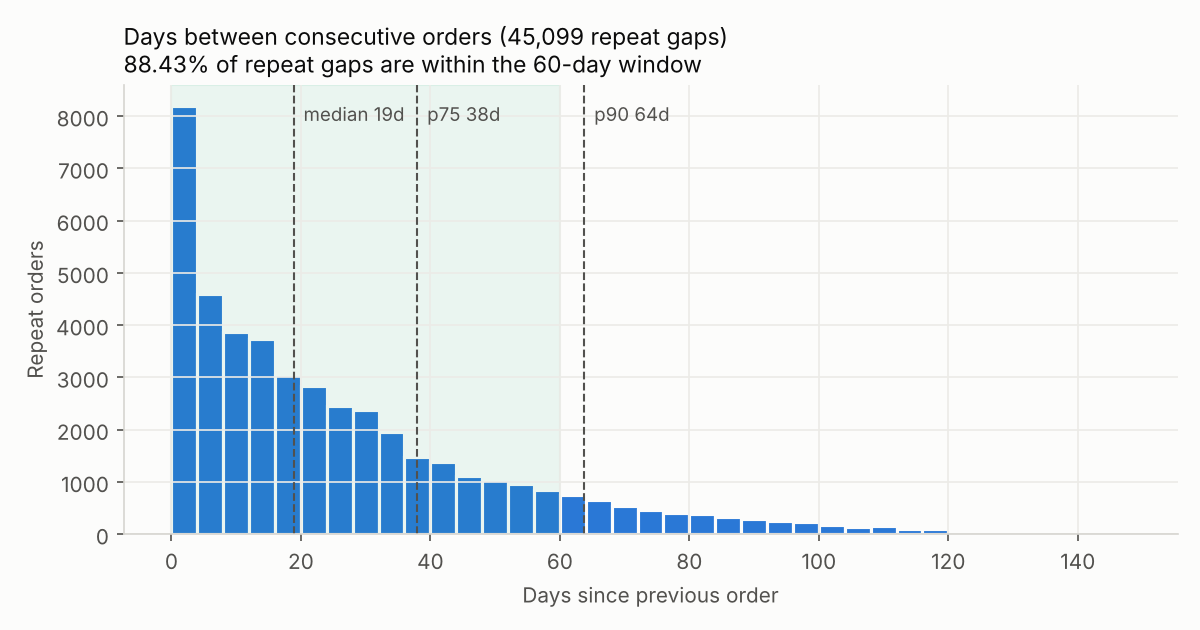

In [4]:
kn("K38", "K39", "K66", "K70", "K73", "K74", "K75")
display(table(3, "customer_status_segments.csv"))
img(3, "p3_01_interpurchase_gap_hist.png")

## Phase 4: EDA, funnel and segments

The session funnel leaks most at the cart: [K30] of cart sessions end without a purchase. Churn falls steeply with the
number of Oct to Dec orders [K48], and RFM segments show where revenue and churn sit: Champions [K86] vs Recent
One-timers [K89].
Report: [04_eda_funnel.md](../reports/04_eda_funnel.md).

,metric,value,unit
id,,,
K30,Session cart abandonment rate (cart sessions with no purchase),87.21%,share
K31,Session conversion (sessions with purchase / all sessions),3.43%,share
K48,Churn by Oct-Dec orders: 1 / 2 / 3 / 4+,90.37% / 70.00% / 51.69% / 33.33%,share
K86,RFM Champions: buyers / revenue share / churn,1545 (2.14%) / 9.86% / 28.67%,mixed
K89,RFM Recent One-timers: buyers / revenue share / churn / churn share,21094 (29.21%) / 19.59% / 88.82% / 30.51%,mixed
K53,Revenue share of top 1% / 10% / 20% customers,11.19% / 43.00% / 59.31%,share


,segment,buyers,revenue,churners,churn_rate,avg_spend,avg_recency,avg_orders,jan_feb_spend,buyer_share,revenue_share,churn_share
0,Champions,1545,379876.90,443.0,28.67,245.88,15.36,5.51,140754.49,2.14,9.86,0.72
1,Loyal,2508,381576.27,1193.0,47.57,152.14,24.43,3.16,125226.56,3.47,9.90,1.94
2,Potential Loyalists,4534,368921.63,2990.0,65.95,81.37,18.40,2.00,108190.64,6.28,9.57,4.87
3,Recent One-timers,21094,754822.43,18735.0,88.82,35.78,18.98,1.00,126376.38,29.21,19.59,30.51
4,Need Attention,13654,648776.80,11782.0,86.29,47.52,40.70,1.15,126128.50,18.90,16.83,19.19
5,Can't Lose Them,80,17995.79,74.0,92.50,224.95,60.12,4.53,831.10,0.11,0.47,0.12
6,At Risk,2513,245756.03,2011.0,80.02,97.79,64.18,2.13,38012.99,3.48,6.38,3.28
7,Hibernating,12634,502661.39,11513.0,91.13,39.79,59.00,1.00,63815.76,17.49,13.04,18.75
8,Lost,13663,553636.32,12662.0,92.67,40.52,81.42,1.00,52926.55,18.92,14.37,20.62


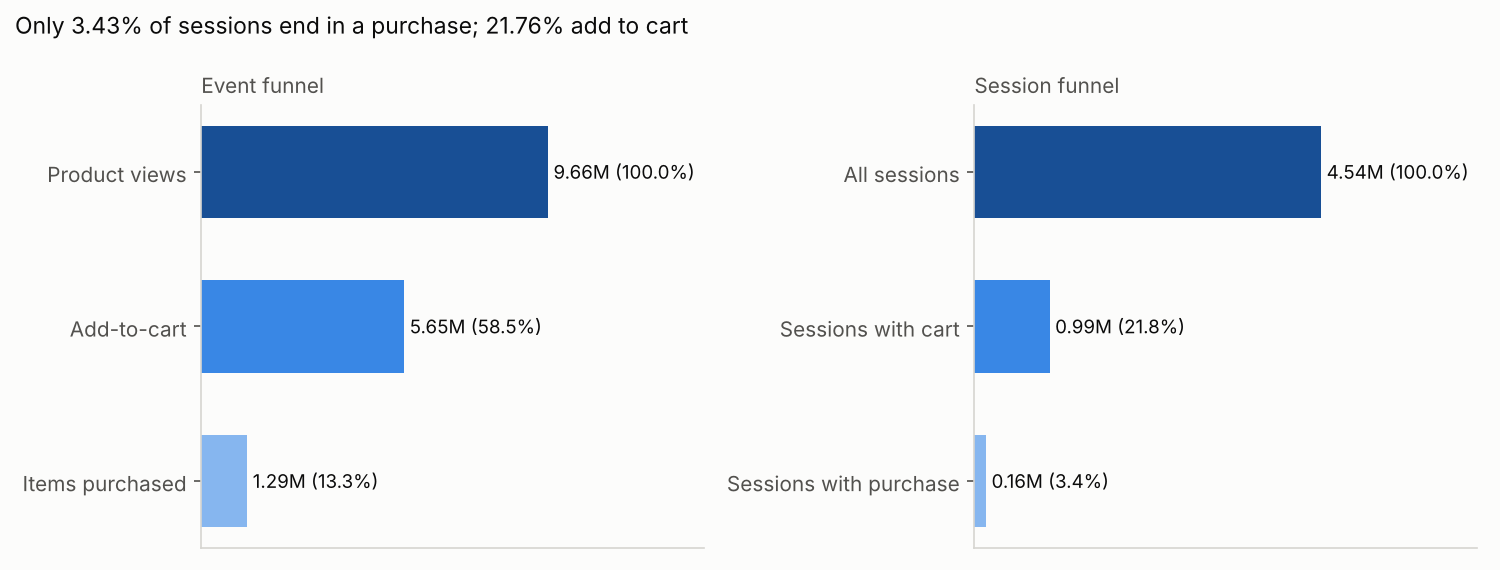

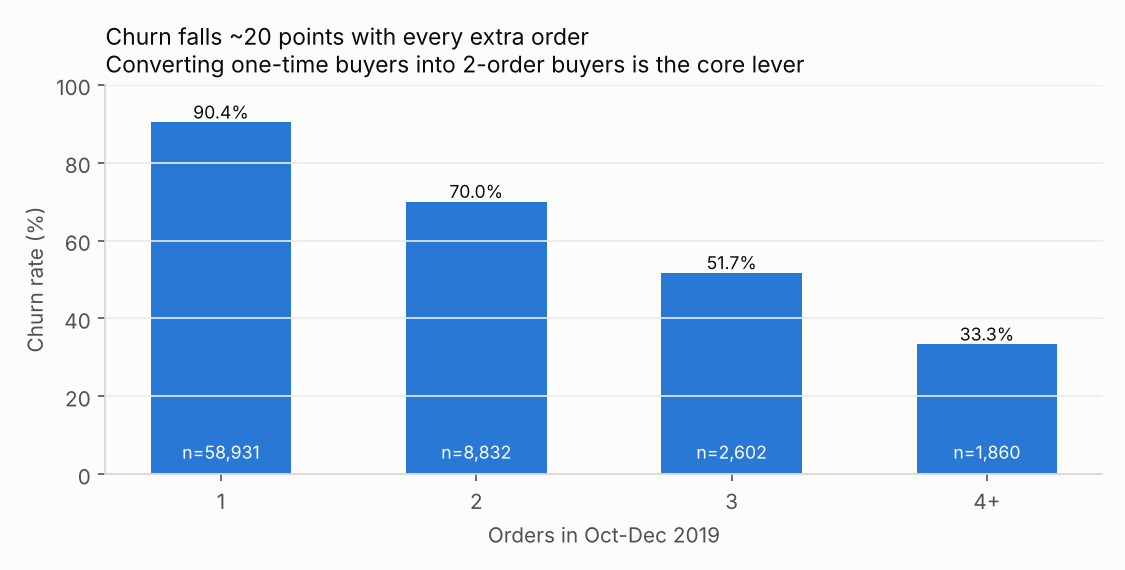

In [5]:
kn("K30", "K31", "K48", "K86", "K89", "K53")
display(table(4, "rfm_segments.csv"))
img(4, "p4_01_funnel_overall.png")
img(4, "p4_17_churn_by_orders.png", width=640)

## Phase 5: hypothesis tests

Six pre-registered tests with Bonferroni correction. Single-order buyers churn far more than repeat buyers [K95];
inactivity in the last 31 days predicts churn [K99]; December-acquired buyers are less likely to make a second order
within 60 days [K98]. The cart-removal hypothesis goes the *opposite* way: buyers who remove more items churn less [K96].
Report: [05_hypothesis_tests.md](../reports/05_hypothesis_tests.md).

In [6]:
kn("K95", "K96", "K98", "K99", "K100")
table(5, "hypothesis_results.csv")[["id", "hypothesis", "test", "p_bonferroni", "significant", "effect_size", "effect_value", "magnitude"]]

,metric,value,unit
id,,,
K95,H1 single vs repeat churn gap,29.09 pp [95% CI 28.23-29.95]; OR 5.93; Cramér's V 0.316; p<1e-300,stat
K96,H2 cart removal: median removal rate churned vs retained,0.350 vs 0.467; rank-biserial -0.163; p=1.7e-162 (n=71568),stat
K98,H3 no 2nd order within 60 days of first order: Dec- vs Nov-acquired,84.41% (n=19702) vs 80.43% (n=26761); +3.98 pp [3.29-4.68]; h=0.105; p=1.8e-28,stat
K99,H4 churn no activity vs any activity in last 31 days,92.93% vs 77.24%; +15.69 pp [15.18-16.20]; OR 3.87; Cramér's V 0.260,stat
K100,H5 median AOV churned vs retained,26.66 vs 37.15 currency units; rank-biserial -0.181; p=3.2e-199,stat


,id,hypothesis,test,p_bonferroni,significant,effect_size,effect_value,magnitude
0,H1,Single-order buyers churn more than repeat buyers,Chi-square (2x2) + two-proportion z-test,0.000000e+00,True,Cramér's V,0.3158,medium
1,H2,Buyers who remove more items from cart churn more,"Mann-Whitney U (cart_remove_rate, churned vs retained)",1.017185e-161,True,Rank-biserial r,-0.1633,small
2,H3,December (holiday) acquired buyers retain worse than November acquired,Two-proportion z-test on 'no 2nd order within 60 days of first order' (recency-free),1.103755e-27,True,Cohen's h,0.1047,negligible
3,H4,Buyers with no site activity in the last 31 days churn more,Chi-square (3 engagement groups x churn) + two-proportion z-test (none vs any),0.000000e+00,True,Cramér's V,0.2599,small
4,H5,Churners had lower average order value than retained buyers,Mann-Whitney U (AOV),1.905933e-198,True,Rank-biserial r,-0.1813,small
5,H6,First-order basket value differs by acquisition month (Oct*/Nov/Dec),Kruskal-Wallis + pairwise Mann-Whitney (Bonferroni x3),1.819502e-92,True,Epsilon-squared,0.0059,negligible


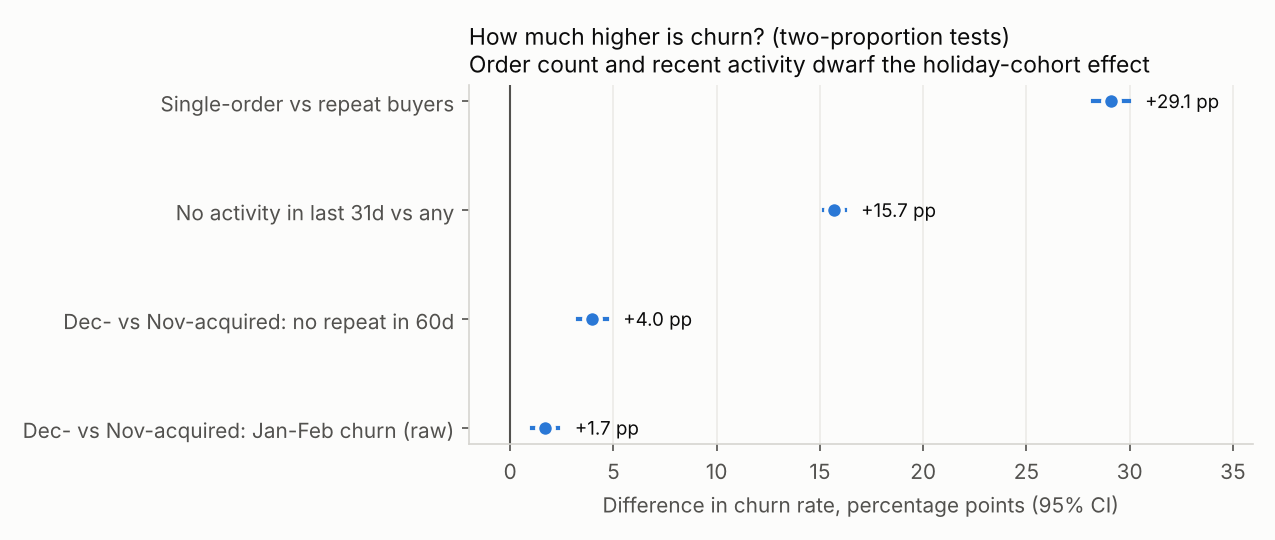

In [7]:
img(5, "p5_01_churn_gaps_ci.png")

## Phase 6: churn prediction

Leak-free features [K103]; four models compared with 5-fold CV [K104]. XGBoost reaches the holdout scores in [K105].
Because 85% of the cohort churns, the useful signal is in the *lowest*-risk buyers: the lowest-risk 10% are several
times more likely to stay than average [K111]. The top SHAP drivers are activity, purchase-timing and tenure features [K112].
A deployment model scores current buyers for Mar to Apr 2020 [K117], [K118].
Report: [06_churn_prediction.md](../reports/06_churn_prediction.md).

In [8]:
kn("K103", "K104", "K105", "K108", "K111", "K112", "K117")
display(table(6, "cv_results.csv"))
display(table(6, "holdout_results.csv")[["model", "roc_auc", "pr_auc_churn", "pr_auc_retained", "accuracy", "f1_churn", "f1_retained"]])

,metric,value,unit
id,,,
K103,Model features used (leak-free),41 features; train 57780 / test 14445 (stratified 80/20; seed 42),count
K104,CV ROC-AUC (5-fold): RFM baseline / logistic / Random Forest / XGBoost,0.7151 / 0.7877 / 0.7919 / 0.7932,AUC
K105,Holdout XGBoost ROC-AUC / PR-AUC churn / PR-AUC retained,0.7973 / 0.9486 / 0.4682 (baselines 0.5 / 0.8502 / 0.1498),AUC
K108,Naive always-churn accuracy vs XGBoost accuracy,85.02% vs 76.61%,share
K111,Lowest-risk 10% / 20%: share who actually stayed; lift,54.50% (lift 3.64) / 42.23%; top 20% lowest-risk capture 56.38% of stayers,share
K112,Top SHAP drivers (XGBoost),n_active_days; events_last_31d; avg_days_between_orders; tenure_days; view_to_cart_rate,rank
K117,Current buyers (Dec 2019-Feb 2020) scored for Mar-Apr 2020,69116 buyers; expected churners 58632.95 (84.83%),users


,model,roc_auc_mean,roc_auc_std,pr_auc_churn_mean,pr_auc_churn_std,pr_auc_retained_mean,pr_auc_retained_std,f1_churn_mean,f1_churn_std
0,RFM baseline (logistic),0.7151,0.0078,0.9188,0.0028,0.3932,0.0088,0.8652,0.0021
1,Logistic regression,0.7877,0.0046,0.9449,0.0019,0.4538,0.0059,0.8261,0.0022
2,Random Forest,0.7919,0.0059,0.9441,0.0026,0.4729,0.0079,0.8802,0.0017
3,XGBoost,0.7932,0.0059,0.9447,0.0026,0.4755,0.0093,0.8540,0.0028


,model,roc_auc,pr_auc_churn,pr_auc_retained,accuracy,f1_churn,f1_retained
0,RFM baseline (logistic),0.7293,0.9245,0.3968,0.7823,0.8660,0.4199
1,Logistic regression,0.7919,0.9472,0.4496,0.7353,0.8263,0.4439
2,Random Forest,0.7977,0.9473,0.4708,0.8068,0.8813,0.4817
3,XGBoost,0.7973,0.9486,0.4682,0.7661,0.8504,0.4641
4,Always predict churn (naive),0.5000,0.8502,0.1498,0.8502,0.9190,0.0000


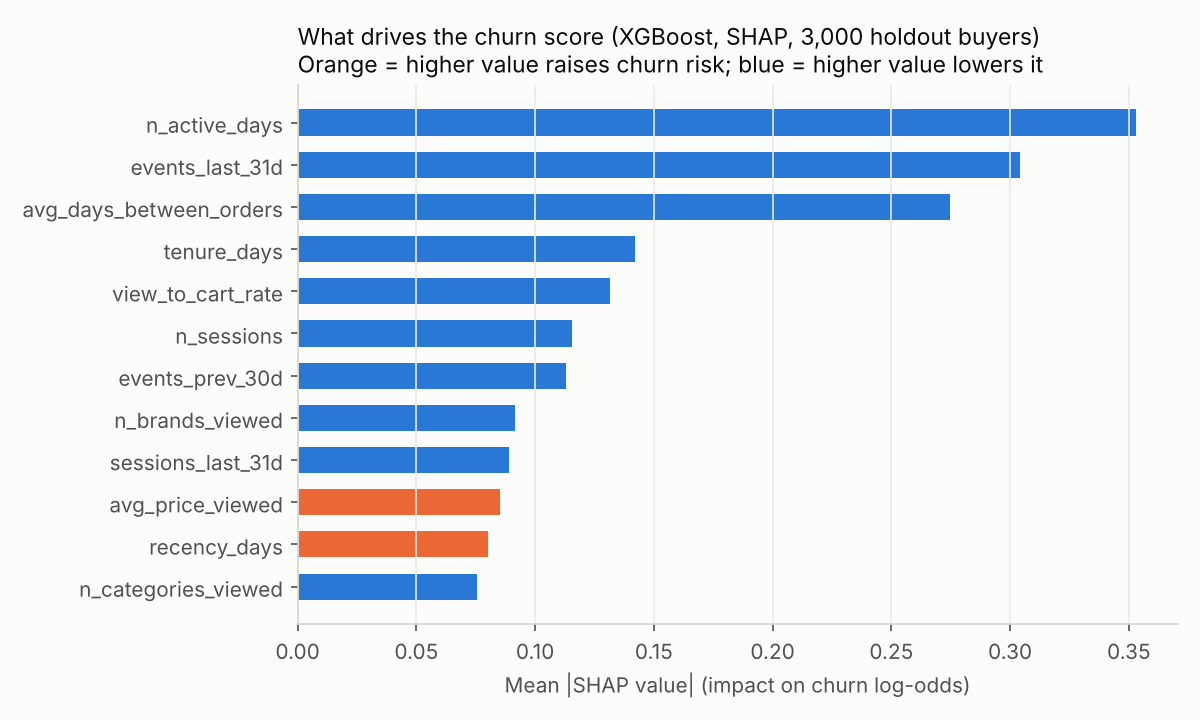

,risk_tier,buyers,avg_score,dec_feb_spend
0,Low (<0.60),5693,0.4143,921088.14
1,Medium (0.60-0.80),3941,0.6737,304759.09
2,High (0.80-0.90),20864,0.8822,1123095.29
3,Very high (>=0.90),38618,0.9119,1214516.23


In [9]:
img(6, "p6_04_shap_importance.png", width=700)
table(6, "current_risk_tiers_mar_apr.csv")

## Phase 7: customer value and retention economics

BG/NBD + Gamma-Gamma give a 90-day CLV for every buyer [K128]. Crossing CLV with churn risk gives four plays; the
**Save now** quadrant (high value, high risk) holds [K132]. Revenue at risk for Mar to Apr is [K130]. Read it as an upper bound: it is 1.41× the store's actual Jan–Feb revenue [K163, K164], so the hard number is the historical one, 74.18% of Oct–Dec revenue from buyers who never returned [K23].
Under the stated assumptions [K134], a win-back offer to Save-now buyers returns [K135] and breaks even at the save rate
in [K136]; offering the same discount to every high-value buyer barely breaks even [K137].
Report: [07_clv_retention_economics.md](../reports/07_clv_retention_economics.md).

,metric,value,unit
id,,,
K128,Predicted 90-day CLV (full refit; all 110518 buyers) total / mean / median,1849732.14 / 16.74 / 9.24,currency units
K130,Revenue at risk Mar-Apr 2020 (sum of churn prob x value if retained),3508675.24 of 4222121.94 value-if-retained (69116 buyers),currency units
K163,Store revenue Jan + Feb 2020 (all buyers; actual 2-month revenue used to sanity-check K130),2494244.14,currency units
K164,Revenue at risk (K130) and value-if-retained relative to a real 2-month revenue (K163): K130 is an upper bound,1.41x / 1.69x,ratio
K23,Share of cohort spend from buyers who churned,74.18%,share
K132,Value x risk: Save now (high value + p>=0.80),12735 buyers; avg churn 0.888; revenue at risk 817779.03 (23.3%),users
K134,Campaign ASSUMPTIONS,contact 0.50 per customer; 10% discount; 40% gross margin; save rate 10% (low end of B7),assumption
K135,Save-now campaign: saves / incremental revenue / cost / net / ROI,1131.1 / 81777.90 / 18068.63 / 14642.53 / +81.0%,currency units
K136,Save-now break-even save rate (40% margin),4.69%,share


,quadrant,buyers,avg_churn_prob,clv_90d,dec_feb_spend,revenue_at_risk,rar_share
0,"Automate (lower value, high risk)",46818,0.9041,522807.3481,1684633.24,2.345801e+06,0.6686
1,"Grow (lower value, lower risk)",1228,0.6737,15840.3558,51683.83,2.699273e+04,0.0077
2,"Protect (high value, lower risk)",8335,0.4954,672601.6725,1168440.99,3.181022e+05,0.0907
3,"Save now (high value, high risk)",12735,0.8882,345264.3199,658700.69,8.177790e+05,0.2331


,targeted,expected_saves,net_profit,roi,break_even_save_rate
"Save now quadrant (high value, high risk)",12735.0,1131.065,14642.5266,0.8104,0.0469
All high-value buyers (top 30% CLV),21070.0,1543.955,49.8915,0.0011,0.0999
All high-risk buyers (p >= 0.80),59553.0,5364.109,54123.2142,0.7474,0.0493
"Everyone (69,116 buyers)",69116.0,5859.726,38986.9652,0.3846,0.0671


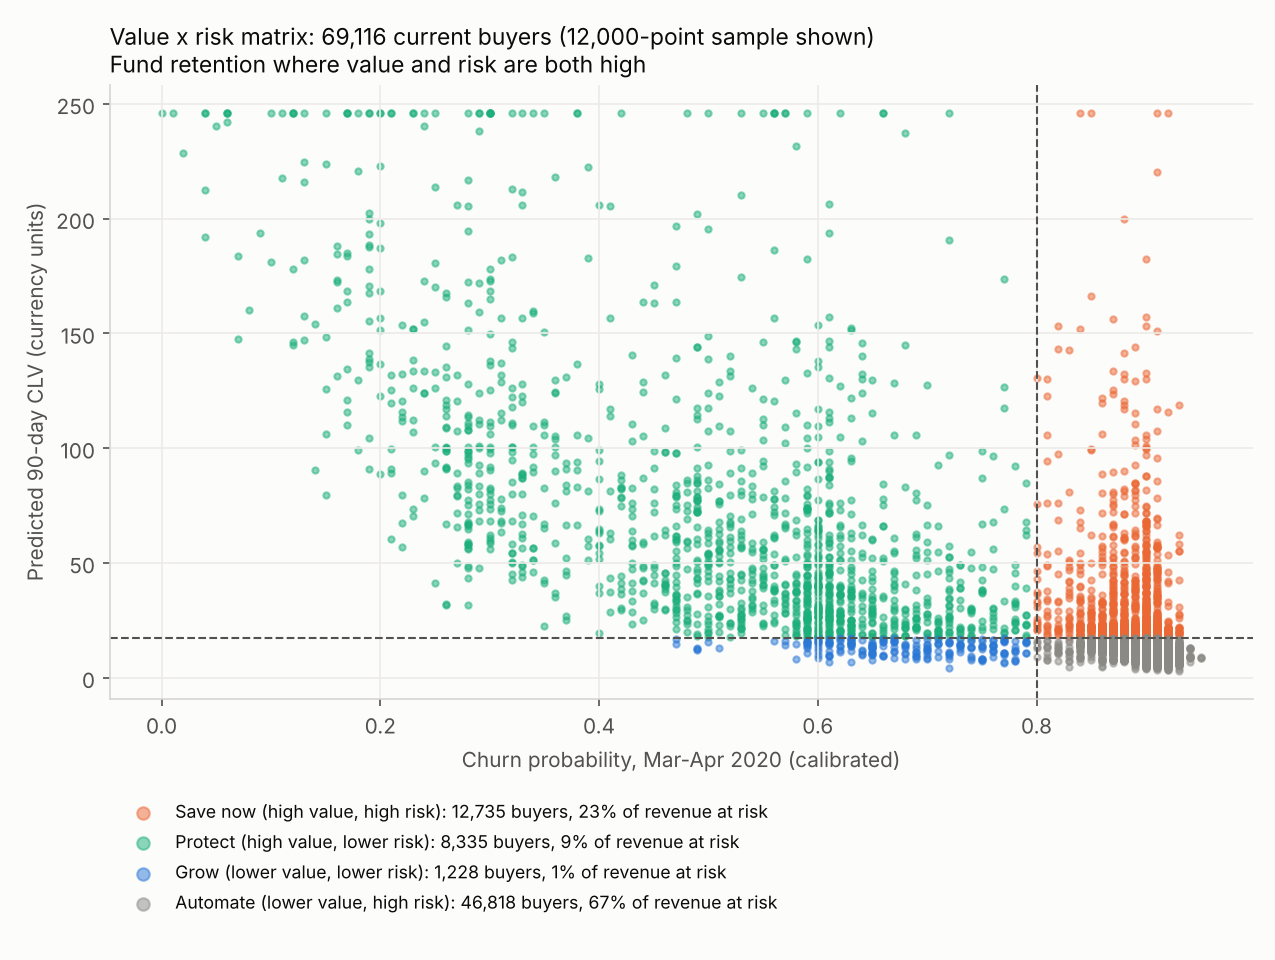

In [10]:
kn("K128", "K130", "K163", "K164", "K23", "K132", "K134", "K135", "K136", "K137", "K140")
display(table(7, "value_risk_matrix.csv"))
display(table(7, "campaign_strategies.csv", index_col=0)[["targeted", "expected_saves", "net_profit", "roi", "break_even_save_rate"]])
img(7, "p7_03_value_risk_matrix.png", width=700)

## Phase 8: dashboards

The same numbers in three tools: a Power BI star schema with a build guide and DAX measures, a standalone HTML
dashboard ([`dashboard/index.html`](../dashboard/index.html)) and an Excel workbook for the retention team
([`dashboard/excel/`](../dashboard/excel/churn_retention_workbook.xlsx)). Every DAX measure is recomputed in pandas from the
exported CSVs and checked against Key Numbers.
Report: [08_dashboards.md](../reports/08_dashboards.md).

In [11]:
pd.read_csv(DASH / "powerbi" / "measure_expected_values.csv")

,measure,expected_value,key_numbers_id
0,Total Revenue,6348267.7,K14
1,Total Orders,155617,K12
2,Buyers,110518,K13
3,AOV,40.79,K15
4,Orders per Buyer,1.408,K16
5,Repeat Purchase Rate,21.09%,K17
6,Cart to View %,58.54%,K28
7,Purchase per Cart %,22.75%,K29
8,Cart Abandonment %,87.21%,K30
9,Session Conversion %,3.43%,K31


## Phase 9: recommendations

Eight actions placed on impact vs effort. The quick wins are the Save-now win-back (R1), silence-trigger nudges (R2)
and a cart-recovery flow (R4); the second-order journey (R3) is the big bet, tested first with a three-arm A/B [K150]
because a blanket 10% offer needs a large uplift to break even while a message alone is cheap [K148].
Report: [09_recommendations.md](../reports/09_recommendations.md).

,metric,value,unit
id,,,
K148,Second-order nudge break-even uplift in 60-day repeat rate: 10% offer to all / message only (0.50 contact) / automat...,9.91 pp / 2.96 pp / 0.59 pp,pp
K149,Second-order nudge at +2 pp uplift (21189 new buyers/month): extra repeat buyers / net gross profit per month automa...,423.8 / +5035.11 vs -21222.86,mixed
K150,Revised A/B: 3 arms (control / message only / message + 10% offer) x 6011 = total / enrolment,18033 / 4 weeks (+9 weeks follow-up = 13 weeks),users
K152,Automate quadrant no-discount nudge (46818 buyers; 2.5% save; 0.10 contact): incremental revenue / cost / net / ROI ...,58645.03 / 4681.80 / 18776.21 / +401% / 0.50%,currency units
K153,Cart recovery: each 1 pp lower session cart abandonment = extra ordering sessions / revenue (Oct-Feb; per month),9872 / 402730.33 (80546.07 per month),mixed


,id,name,impact,effort
0,R1,Save-now win-back,High,Low
1,R2,Silence-trigger nudges,High,Low
2,R3,Second-order journey (A/B first),High,Medium
3,R4,Cart-recovery flow,High,Low
4,R5,Protect without discounts,Medium,Medium
5,R6,Post-holiday follow-up,Low,Low
6,R7,Fix brand data at source,Medium,High
7,R8,Monthly rescoring + holdouts,Medium,Medium


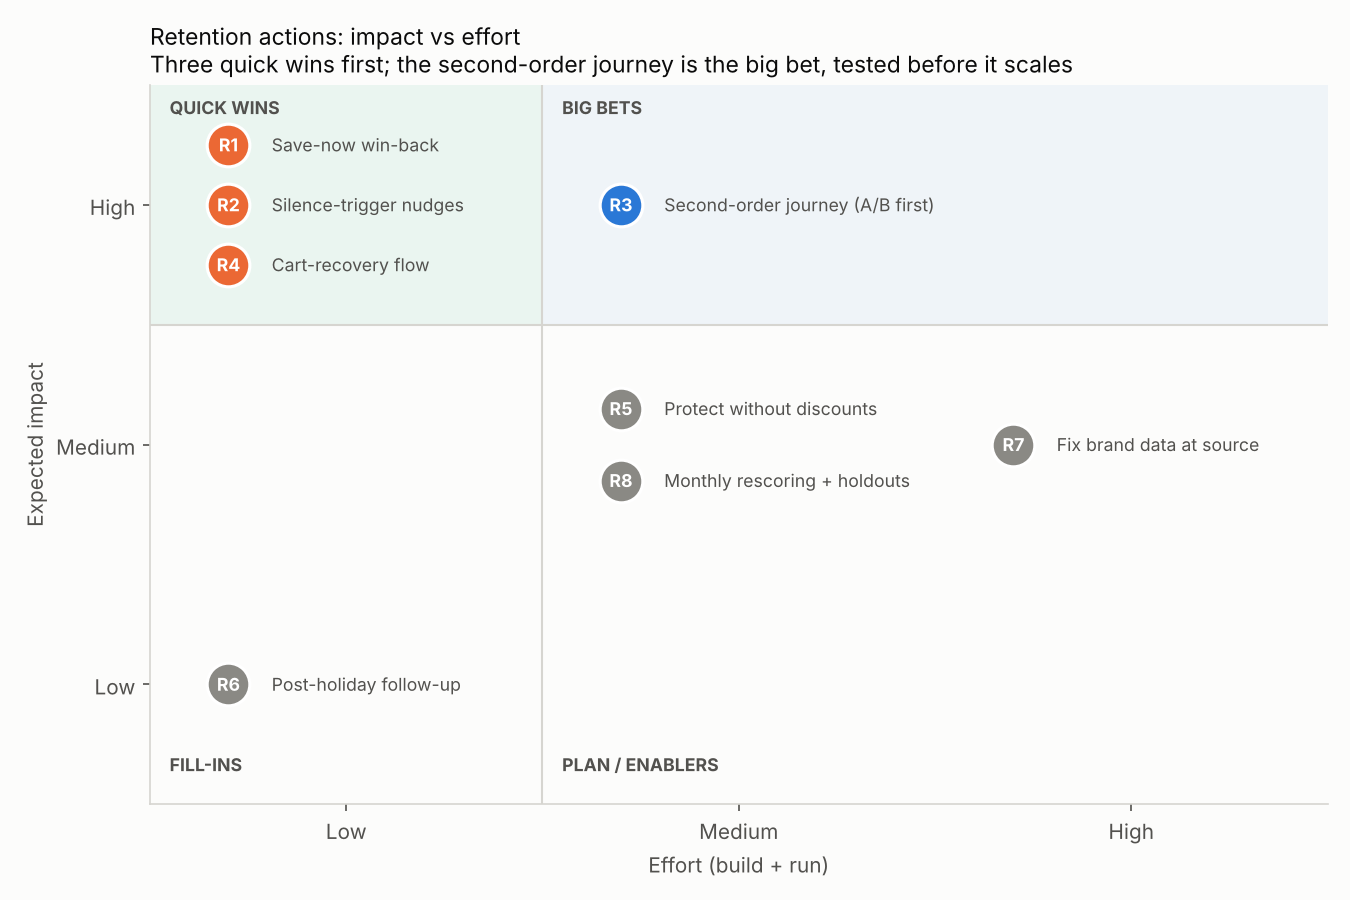

In [12]:
kn("K148", "K149", "K150", "K152", "K153")
display(table(9, "impact_effort.csv"))
img(9, "p9_01_impact_effort.png", width=720)

## Reproduce

```bash
pip install -r requirements.txt
python run_all.py          # Phases 1-9, about 6 minutes on 4 cores (Phase 6 model CV dominates)
jupyter nbconvert --to notebook --execute --inplace notebooks/churn_retention_walkthrough.ipynb
```